# 02 · Manifold — principal-curve trajectory (malignant manifold)

Peng's malignant manifold is a **single, continuous 2-D cloud** (Gate 1 GO) with
a modest overall UMAP aspect ratio (~1.1, below). We fit a **non-branching
principal curve** (ElPiGraph) as the readout axis and root it at the
developmental-origin criterion (Gast/pSom-high, Crest-low), producing the
pseudotime coordinate on which notebook 03 evaluates Gate 2. A branching PPT tree
was rejected upstream: its forks carry near-identical module values (geometric
artifacts on a compact cloud, not biological arms).

**Fitting is deliberately generous to the GO hypothesis.** The bending
regularisation is set loose enough (`epg_mu=50`, not the stiffer `100`) that the
backbone reaches every module-high corner of the cloud — we verify the node span
comes within ~2 UMAP units of both the Gast/pSom-high and Crest-high centroids below
(the Crest-high centroid sits just beyond the node cloud, ~2 units from the nearest node). This gives the
embryonic pattern every chance to appear along the axis. The map that emerges,
however, already foreshadows the Gate-2 NO-GO: the three module-high territories
sit at **three separate corners** of the cloud (a triangle, not a body→terminus
line), Gast and pSom are **spatially mutually exclusive** rather than co-located,
and along the rooted axis Gast and pSom move in **opposite** directions. Notebook
03 makes this quantitative. Deliverable: `manifold.h5ad`, `manifold.pdf`.

In [ ]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load the processed manifold (single continuous compartment)
The whole malignant manifold is carried forward — notebook 01 found no separable
cycling/embryonic lobes (one Leiden lobe at res=0.15, uniform ~7% cycling). Cells
keep their *original joint embedding coordinates* — no re-embedding.

In [ ]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
sub = adata.copy()                                  # single compartment
print('manifold:', sub.shape[0], 'cells on the joint embedding')
xy = sub.obsm['X_umap']
from numpy.linalg import svd
c = xy - xy.mean(0); u,s,vt = svd(c, full_matrices=False)
print(f'UMAP aspect ratio (major/minor std): {s[0]/s[1]:.2f}  (~1 -> isotropic blob, no preferred axis)')

manifold: 7945 cells on the joint embedding
UMAP aspect ratio (major/minor std): 1.15  (~1 -> isotropic blob, no preferred axis)


### Score embryonic modules and smooth for geography
The three developmental signatures (Gastrulation / Somitogenesis / Neural-crest)
are scored against the shared **union** control pool so scores are directly
comparable, then graph-smoothed (3 propagation steps) to read *geography* rather
than single-cell dropout. Scored here (before rooting) so the root criterion can
use them.

In [ ]:
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(sub.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src,lab in label.items():
    g = feat[src].loc[feat[src].isin(sub.var_names)]
    sc.tl.score_genes(sub, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
A = (sub.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
Smat = sub.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): Smat = A @ Smat
for j,lab in enumerate(['Gast','pSom','Crest']): sub.obs[lab+'_sm'] = Smat[:,j]
print('smoothed-module spatial correlations (Pearson):')
print('  Gast~pSom  =%+.3f' % np.corrcoef(sub.obs.Gast_sm, sub.obs.pSom_sm)[0,1])
print('  Gast~Crest =%+.3f' % np.corrcoef(sub.obs.Gast_sm, sub.obs.Crest_sm)[0,1])
print('  pSom~Crest =%+.3f' % np.corrcoef(sub.obs.pSom_sm, sub.obs.Crest_sm)[0,1])
# --- module-territory geometry: hub/body vs three separate corners ---
body = sub.obs['Gast_sm'].values + sub.obs['pSom_sm'].values
Cs = sub.obs['Crest_sm'].values
Gs = sub.obs['Gast_sm'].values; Ps = sub.obs['pSom_sm'].values
bhi = body >= np.quantile(body, .9); chi = Cs >= np.quantile(Cs, .9)
bc = xy[bhi].mean(0); cc = xy[chi].mean(0)
cent = {m: xy[v >= np.quantile(v,.9)].mean(0) for m,v in [('Gast',Gs),('pSom',Ps),('Crest',Cs)]}
def _ang(o,a,b):
    u=cent[a]-cent[o]; w=cent[b]-cent[o]
    return np.degrees(np.arccos(np.clip(u@w/(np.linalg.norm(u)*np.linalg.norm(w)),-1,1)))
print('module-high centroids (UMAP):', {m:c.round(2).tolist() for m,c in cent.items()})
print(f'triangle angles: Gast={_ang("Gast","pSom","Crest"):.0f} '
      f'pSom={_ang("pSom","Gast","Crest"):.0f} Crest={_ang("Crest","Gast","pSom"):.0f} deg '
      f'(one ~180 => collinear body->terminus axis; all ~60 => three separate territories)')
# co-location test: do Gast & pSom occupy the SAME cells (hub/body) or exclude?
gh = Gs>=np.quantile(Gs,.75); ph = Ps>=np.quantile(Ps,.75)
print(f'Gast&pSom joint-high (top quartile each) = {(gh&ph).mean()*100:.1f}% '
      f'vs {0.25*0.25*100:.1f}% independence expectation '
      f'({"co-located hub/body" if (gh&ph).mean()>0.0625 else "MUTUALLY EXCLUSIVE -> no hub/body"})')

Gast: 77/81 genes present
pSom: 90/98 genes present
Crest: 100/104 genes present
smoothed-module spatial correlations (Pearson):
  Gast~pSom  =-0.412
  Gast~Crest =-0.226
  pSom~Crest =-0.612
module-high centroids (UMAP): {'Gast': [-1.0700000524520874, 7.150000095367432], 'pSom': [2.109999895095825, 4.610000133514404], 'Crest': [4.980000019073486, 7.670000076293945]}
triangle angles: Gast=44 pSom=95 Crest=42 deg (one ~180 => collinear body->terminus axis; all ~60 => three separate territories)
Gast&pSom joint-high (top quartile each) = 0.8% vs 6.2% independence expectation (MUTUALLY EXCLUSIVE -> no hub/body)


### Fit the principal curve (ElPiGraph)
`Nodes=20`, moderate bending regularisation (`epg_mu=50`) — loose enough for the
backbone to reach both the Gast/pSom-high and Crest-high corners (the node cloud comes within ~2 UMAP units of each corner, verified below), stiff enough to stay fold-free. The curve is non-branching
by construction; we report its tips/forks and the fold self-approach ratio (min
distance between graph-non-adjacent nodes, in units of median edge length; >1 =
fold-free), and confirm the node cloud comes within ~2 UMAP units of the Crest-high centroid so the
Crest terminus is actually sampled.

In [ ]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3:
                dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks

with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=50.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print(f'curve: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
Fnodes = sub.uns['graph']['F'].T
dcrest = np.min(np.linalg.norm(Fnodes - cc, axis=1))
dbody  = np.min(np.linalg.norm(Fnodes - bc, axis=1))
edge_ok = dcrest < np.linalg.norm(bc-cc)/2
print(f'curve node span x[{Fnodes[:,0].min():.1f},{Fnodes[:,0].max():.1f}] y[{Fnodes[:,1].min():.1f},{Fnodes[:,1].max():.1f}]')
print(f'nearest node to Crest-high centroid = {dcrest:.2f}, to body-high = {dbody:.2f} '
      f'-> curve reaches both ends: {edge_ok}')

curve: 2 tips, 0 forks | fold self-approach ratio = 2.46 (>1 = fold-free)
curve node span x[-0.7,5.5] y[3.8,7.3]
nearest node to Crest-high centroid = 1.96, to body-high = 1.04 -> curve reaches both ends: True


### Derive the root (data-driven) and compute pseudotime
The root is set to the curve tip maximising `Gast+pSom-Crest` (the developmental
origin per the protocol). Pseudotime increases from that origin along the axis.
The gradient readout below is the substrate for Gate 2 in notebook 03. Note that
Gast and pSom already move in **opposite** directions along this axis — the
signature of the NO-GO documented above (they are not a co-varying body), which
notebook 03 confirms through the joint-high depletion and sub-region sweep.

In [ ]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for t in tps:
    m = np.isin(hard, np.where(D[t]<=3)[0])
    info[t] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {t}: Gast={info[t][0]:+.4f} pSom={info[t][1]:+.4f} Crest={info[t][2]:+.4f}')
root = int(max(tps, key=lambda t: info[t][0]+info[t][1]-info[t][2]))
print('derived root = tip', root, '(max Gast+pSom-Crest)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
print('gradient along pseudotime (Spearman rho):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p = spearmanr(t, sub.obs[s]); print(f'  {s}: rho={rho:+.3f} p={p:.1e}')

tip 0: Gast=-0.0398 pSom=+0.0902 Crest=-0.0507
tip 2: Gast=-0.0571 pSom=+0.0932 Crest=-0.0470
derived root = tip 0 (max Gast+pSom-Crest)
gradient along pseudotime (Spearman rho):
  Gast_sm: rho=-0.564 p=0.0e+00
  pSom_sm: rho=+0.107 p=1.3e-21
  Crest_sm: rho=+0.098 p=2.7e-18


### Reorient to house style (pseudotime left → right)
The panel is oriented using only raw UMAP coordinates with a discrete axis flip
(no rotation/interpolation — those are brittle). We pick, among the four
axis-aligned reflections, the one that lands low pseudotime on the left with the
blob upright, and assert the result increases left→right.

In [ ]:
xy = sub.obsm['X_umap'].copy(); t = sub.obs['t'].values
# choose the axis whose coordinate best tracks pseudotime, orient it increasing
cx = abs(np.corrcoef(xy[:,0], t)[0,1]); cy = abs(np.corrcoef(xy[:,1], t)[0,1])
if cy > cx:                                     # pseudotime axis is vertical -> make horizontal
    xyr = np.column_stack([xy[:,1], xy[:,0]])
else:
    xyr = xy.copy()
if np.corrcoef(xyr[:,0], t)[0,1] < 0:           # ensure low pt on the left
    xyr[:,0] = -xyr[:,0]
r = float(np.corrcoef(xyr[:,0], t)[0,1])
assert r > 0, f'pseudotime not left->right (corr={r:+.2f})'
sub.obsm['X_umap_lin'] = xyr
print(f'orientation: axis-aligned reflection (no rotation); corr(x_lin, pseudotime) = {r:+.2f}')

orientation: axis-aligned reflection (no rotation); corr(x_lin, pseudotime) = +0.86


### Save manifold + trajectory figure (deliverable)

saved manifold.h5ad + manifold.pdf


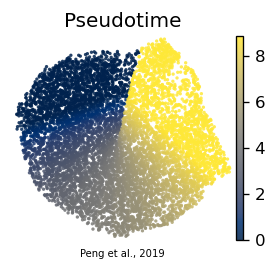

In [ ]:
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = sub.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.05
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(2.7, 2.2))
sc.pl.umap(plot, color='t', cmap='cividis', size=16, alpha=.85, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py); ax.set_aspect('equal')
ax.text(.5,-.08,'Peng et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf')